# Render CT along a mesh segment's normals
Select a registered segment geometry, sample its central surface and offsets
`(-1,0,+1)`, and display the three CT images side by side. Here offsets are in
source-volume voxels: one voxel is 2.4 µm for the selected scan. The reader takes
physical micrometers. This uses the mesh's published parameterized `tifxyz`
coordinate surface and requires no ink labels.


In [1]:
from pathlib import Path
import os

import numpy as np
from _display import panel
from vc_reader import load
from vc_reader.reader import MemoryCache
CACHE = Path(os.environ.get('VC_EXAMPLE_CACHE', '/tmp/vc-reader-notebooks'))
METADATA = os.environ.get('VC_EXAMPLE_METADATA')  # optional local snapshot
options = dict(cache_dir=CACHE, threads=1,
               memory_cache=MemoryCache(64 << 20))
catalog = load(METADATA) if METADATA else load()


## 1. Select the segment and its geometry in the CT volume


In [2]:
from dataclasses import replace
paris = catalog.samples['PHercParis4']
volume = paris.volumes['20260411134726']
segment = paris.segments['20230702185753']
for asset in segment.geometry.filter(artifact_kind='tifxyz-transformed'):
    print('Geometry registered to volume', asset.volume.id)
geometry = segment.geometry.get(artifact_kind='tifxyz-transformed', volume=volume.id)
surface = replace(geometry.source.registration.surface, tifxyz_mask=False)
# This published bundle has no optional mask.tif; invalid XYZ/quad support is still checked.
print('Selected surface:', surface.id)
print('Coordinate frame:', surface.sample_id, surface.volume_id)
print('Source voxel spacing (um):', volume.pixel_size_um)


Geometry registered to volume 20260608103018
Geometry registered to volume 20260310170716
Geometry registered to volume 20230205180739
Geometry registered to volume 20260411134726
Selected surface: catalog:PHercParis4/segment/20230702185753/snapshot/de38ba456eedfa4e0c4c6d6b4e093f4664d635eae551bfbe923bbdf6dc4ec58d/data/8
Coordinate frame: PHercParis4 20260411134726
Source voxel spacing (um): 2.4


## 2. Render three physical offsets
Start/size are full-resolution UV **YX pixels**, not CT ZYX coordinates. Normals follow
`dP/du × dP/dv`; the sign refers to that orientation. Offset zero follows the
curved sheet rather than a global axial CT plane. Geometry validity remains
per layer. The returned image has shape `(C,D,H,W)` in the requested offset order.


In [3]:
UV_START = (7328, 17984)
UV_SIZE = (64, 64)
OFFSETS_VOXELS = (-1, 0, 1)
offsets_um = tuple(offset * volume.pixel_size_um for offset in OFFSETS_VOXELS)
with volume.open_aligned({}, level=0, backend='cpu', **options) as reader:
    rendered = reader.render_surface(surface, UV_START, UV_SIZE, offsets_um=offsets_um)
    stats = reader.stats()
print('CDHW:', rendered.image.data.shape)
print('Offsets (um):', offsets_um)
print('Valid samples per offset:', rendered.image.valid.sum(axis=(0, 2, 3)).tolist())
assert rendered.image.data.shape == (1, 3, *UV_SIZE)
assert rendered.image.valid.any()


CDHW: (1, 3, 64, 64)
Offsets (um): (-2.4, 0.0, 2.4)
Valid samples per offset: [4096, 4096, 4096]


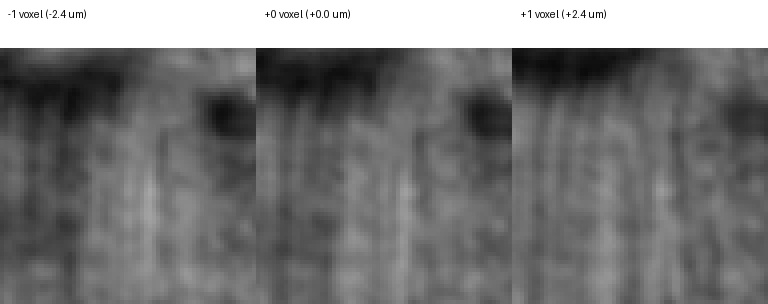

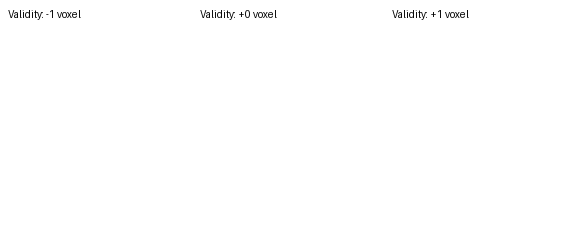

In [4]:
display(panel([(f'{offset:+d} voxel ({um:+.1f} um)',
                rendered.image.data[0, i].astype(np.float32)/255)
               for i, (offset, um) in enumerate(zip(OFFSETS_VOXELS, offsets_um))]))
display(panel([(f'Validity: {offset:+d} voxel', rendered.image.valid[0, i])
               for i, offset in enumerate(OFFSETS_VOXELS)], size=192))


## 3. Use the same operation on CUDA
For a consumer already running on the GPU, select `backend='cuda'`. The reader
returns device arrays. Downloading here is solely for comparison/display; a
training consumer can retain device storage. This section is optional.


In [5]:
from vc_reader.cuda import is_available
if is_available():
    with volume.open_aligned({}, level=0, backend='cuda', **options) as reader:
        device_sample = reader.render_surface(surface, UV_START, UV_SIZE, offsets_um=offsets_um)
    np.testing.assert_allclose(device_sample.image.data.numpy(), rendered.image.data, atol=.03, rtol=2e-5)
    np.testing.assert_array_equal(device_sample.image.valid.numpy(), rendered.image.valid)
    print('CPU/CUDA layers agree.')
else:
    print('CPU render completed; CUDA comparison needs a CUDA build and device.')


CPU/CUDA layers agree.


To change the view, select another registered segment/volume and a valid UV
patch, or change `OFFSETS_VOXELS`. For absolute physical offsets, pass your desired
micrometer tuple directly. Keep readers open across multiple patches to reuse
geometry, chunk and sampling caches; context managers release them afterwards.
